# Reading SCHISM `hgrid.gr3` grids with `pyramids-mesh`

[SCHISM](http://ccrm.vims.edu/schismweb/) is a cross-scale hydrodynamic model. Its horizontal grid is the ASCII **`hgrid.gr3`** file — the same node/element layout as ADCIRC's `fort.14`, plus open- and land-boundary sections. The per-node value column holds the **bathymetric depth**.

`pyramids-mesh` registers a `schism` **driver** that parses `hgrid.gr3` into a `UgridDataset`/`Mesh2d`. This notebook reads the California DWR teaching grid and walks read → explore → plot → GIS.

## 1. Pin the plotting backend

Figures are rendered through `cleopatra` (matplotlib). So the notebook runs identically under
CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`,
and define a tiny `show()` helper that grabs the current figure, saves it to an in-memory PNG and
embeds it inline. With `Agg` a bare `plt.show()` embeds nothing, so every plot below ends with a
`show()` call instead.

In [1]:
import os
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
import pyramids  # noqa: F401  (must be first)
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
from pathlib import Path

## 3. Locate the data

The notebook lives in `docs/examples/`, so `examples/data/` is two levels up. We pass a `pathlib.Path` to the reader (never a string).

In [3]:
DATA = Path("../../examples/data")
src = DATA / "schism" / "hgrid.gr3"
sorted(p.name for p in src.parent.iterdir())

['SOURCE.txt', 'hgrid.gr3']

## 4. Read the mesh

We name the driver explicitly: `driver="schism"`. `read_file` dispatches to it and returns a `UgridDataset` wrapping a `Mesh2d`.

In [4]:
ds = UgridDataset.read_file(src, driver="schism")
ds

UgridDataset(mesh='mesh2d', n_node=2639, n_face=4636, n_edge=0, variables=['node_z'])

## 5. Explore the mesh

Node/face counts, CRS, the attached data variables and the bounding box. This grid has 2639 nodes and 4636 triangles, with coordinates in **projected metres** (bounds run 0–56000 m east, −10400–10400 m north) — though the file declares no EPSG code, so `crs`/`epsg` are `None`.

In [5]:
{"n_node": ds.n_node, "n_face": ds.n_face,
 "epsg": ds.epsg, "crs": ds.crs,
 "variables": ds.data_variable_names,
 "bounds": tuple(round(b, 3) for b in ds.bounds)}

{'n_node': 2639,
 'n_face': 4636,
 'epsg': None,
 'crs': None,
 'variables': ['node_z'],
 'bounds': (0.0, -10400.0, 56000.0, 10400.0)}

`summary()` tabulates every data variable's count/min/max/mean/std.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,2639,0.5,10.0,4.41068,2.799775


`node_z` is the per-node bathymetric depth the driver read from `hgrid.gr3`'s value column. The `summary()` above shows it spanning 0.5–10.0 in model units.

## 6. Mesh geometry

The `Mesh2d` exposes node coordinates, the `(n_face, k)` face-node connectivity, per-face areas and centroids — all plain numpy arrays.

In [7]:
m = ds.mesh
fnc = np.asarray(m.face_node_connectivity.data)
cen = np.asarray(m.face_centroids)
{"fnc_shape": fnc.shape, "first_element": fnc[0].tolist(),
 "centroids_shape": cen.shape,
 "mean_face_area": float(np.asarray(m.face_areas).mean())}

{'fnc_shape': (4636, 3),
 'first_element': [0, 2, 1],
 'centroids_shape': (2, 4636),
 'mean_face_area': 122985.2028478492}

A `(n_face, 3)` table means every element is a triangle. Centroids come back `(2, n_face)`.

## 7. Wireframe

`plot_outline()` draws the bare element skeleton — the fastest way to read the mesh's shape and where it is refined.

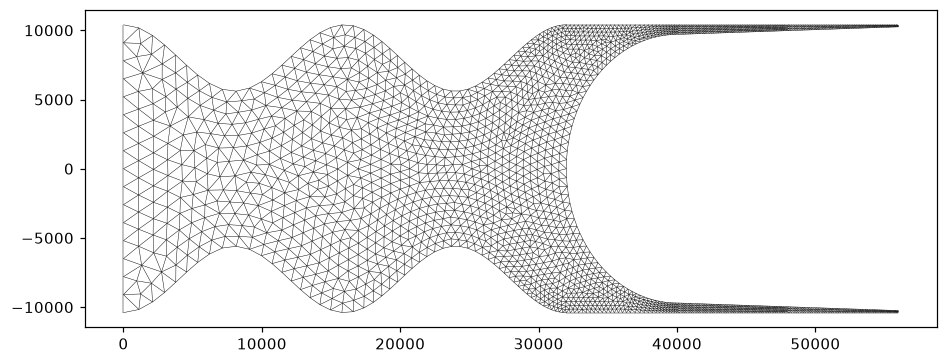

In [8]:
ds.plot_outline(); show()

## 8. Data map

`node_z` is the per-node bathymetric depth the driver read from `hgrid.gr3`'s value column. The `summary()` above shows it spanning 0.5–10.0 in model units.

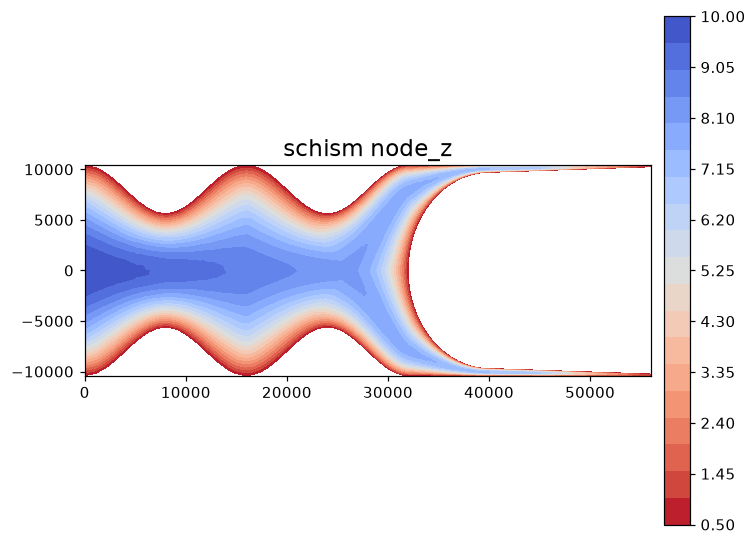

In [9]:
ds.plot("node_z", cmap="viridis", colorbar=True,
        title="schism node_z"); show()

## 9. GIS operations for free

The mesh is a pyramids object, so the vector/GIS layer applies unchanged. Convert to a GeoDataFrame — one polygon per element. `to_geodataframe()` returns just the geometry column, so we attach each element's **area** and let geopandas colour by it; smaller cells reveal where the mesh is refined.

In [10]:
gdf = ds.to_geodataframe()
gdf["face_area"] = np.asarray(ds.mesh.face_areas)
gdf.head()

,geometry,face_area
0,"POLYGON ((56000 -10400, 56000 -10350, 55831.58...",4210.5000
1,"POLYGON ((55831.58 -10400, 55831.58 -10348.07,...",4373.0253
2,"POLYGON ((56000 -10350, 56000 -10300, 55831.58...",4210.5000
3,"POLYGON ((55663.16 -10400, 55663.16 -10346.14,...",4535.5506
4,"POLYGON ((55831.58 -10348.07, 55831.58 -10296....",4373.0253


Colour the elements by area with geopandas — the per-element column rides along with the geometry:

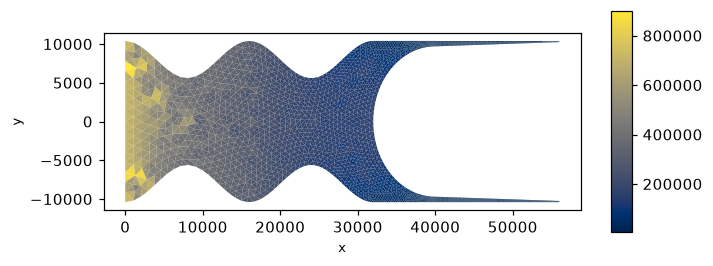

In [11]:
gdf.plot(column="face_area", cmap="cividis", figsize=(7, 5),
         legend=True); show()

The **bounding polygon** is the dissolved outer hull — the mesh's true footprint — drawn here in red over the wireframe.

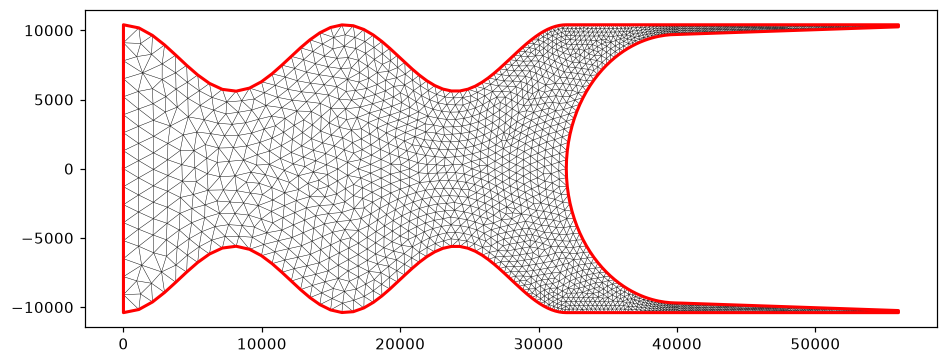

In [12]:
poly = ds.bounding_polygon()
ax = ds.plot_outline().ax
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="red", lw=2); show()

**Connectivity.** `sparse_adjacency()` is the node-node adjacency (SciPy sparse); `connected_components()` labels each node's component. One component = one unbroken mesh.

In [13]:
adj = ds.sparse_adjacency()
comp = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(comp).size)}

{'adjacency_shape': (4636, 4636), 'nnz': 13268, 'n_components': 1}

`exterior_edges()` returns the boundary edges (the mesh rim); `circumcenters()` the triangle circumcentres (the dual-mesh vertices used in finite-volume schemes).

In [14]:
ext = ds.exterior_edges()
cc = ds.circumcenters()
{"exterior_edges": int(np.asarray(ext).shape[0]),
 "circumcenters_shape": np.asarray(cc).shape}

{'exterior_edges': 640, 'circumcenters_shape': (4636, 2)}

**Spatial subset.** `subset_by_bounds` keeps only faces inside a box, renumbering the connectivity. We take the mesh's own bounds and crop to its lower-left quadrant.

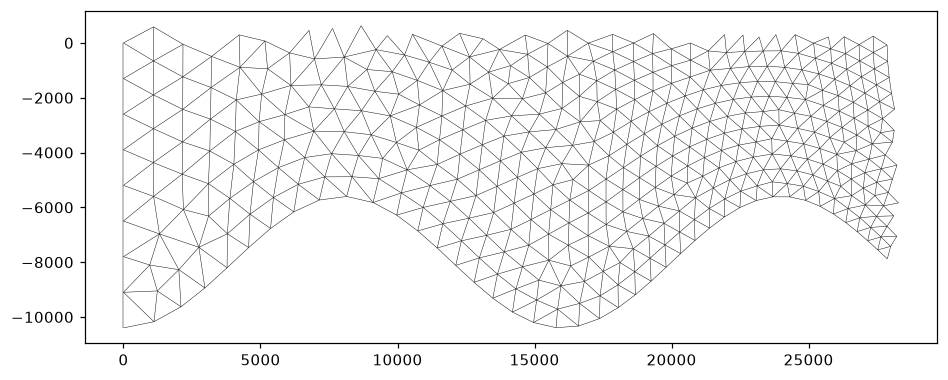

In [15]:
x0, y0, x1, y1 = ds.bounds
sub = ds.subset_by_bounds(x0, y0, (x0 + x1) / 2, (y0 + y1) / 2)
sub.plot_outline(); show()

Only the faces inside the quadrant survive, with their connectivity renumbered:

In [16]:
{"faces_kept": sub.n_face, "of_total": ds.n_face}

{'faces_kept': 770, 'of_total': 4636}

**Export.** `to_file` writes the mesh through any writer driver — here an SMS `2dm` grid in a temp folder.

In [17]:
import tempfile
out = Path(tempfile.gettempdir()) / "hgrid.2dm"
ds.to_file(out, driver="2dm")
{"written": out.name, "exists": out.exists()}

{'written': 'hgrid.2dm', 'exists': True}

And `to_xarray()` hands the mesh and its variables to the xarray ecosystem:

In [18]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)

('Dataset',
 ['mesh2d', 'mesh2d_node_x', 'mesh2d_node_y', 'mesh2d_face_nodes', 'node_z'])

## 10. What needs more than a mesh

- **`to_crs(epsg)`** needs a source CRS. `hgrid.gr3` carries projected metres but declares no EPSG code, so `ds.epsg is None`, so `to_crs` is skipped.
- **`rasterize_like` / `regrid`** need a *reference grid* to sample onto; with only the mesh in hand there is no target, so they are out of scope for this read-only tour.

## Takeaway

`UgridDataset.read_file(path, driver="schism")` turns the native schism grid into a first-class pyramids mesh. Exploration, plotting, GeoDataFrame conversion, bounding polygons, connectivity analysis, spatial subsetting and export are all inherited from pyramids — `pyramids-mesh` only added the reader.